---
# Project: Will the client open a term deposit?

**Goal in one sentence:** a bank calls clients and offers them a term deposit. We want a model that tells us **which clients will probably say "yes"**, so the bank can call them first.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, f1_score
from xgboost import XGBClassifier
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK
import shap

pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42

## 1. Load the data and first look

In [2]:
df = pd.read_csv('data/bank-additional-full.csv', sep=';')
print('Shape:', df.shape)
df.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
# Missing values and duplicates
print('Missing values (NaN):', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

# In this dataset missing values are written as the word 'unknown'
unknown_counts = (df == 'unknown').sum()
unknown_counts[unknown_counts > 0]

Missing values (NaN): 0
Duplicate rows: 12


job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

**What we see:**
- 41,188 clients, 20 features + target `y`.
- There are **no NaN values**, but some columns have the value `'unknown'`. This is the "hidden" missing value. We will keep `'unknown'` as its own category, because "the bank does not know" can also be useful information (for example, `default = unknown` may mean the client hides something).
- There are a few duplicate rows. We will delete them.

y
0    36537
1     4639
Name: count, dtype: int64
Share of "yes": 11.3 %


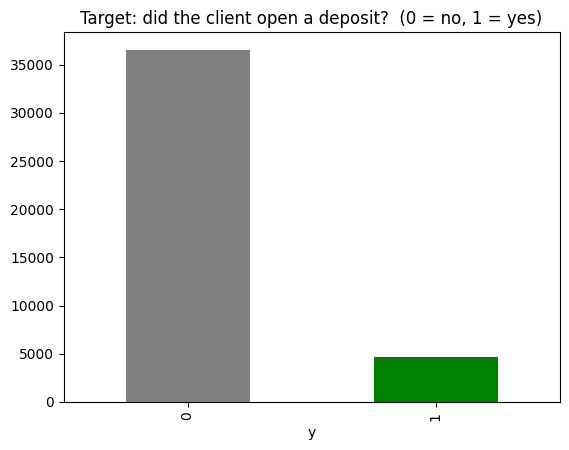

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
df['y'] = (df['y'] == 'yes').astype(int)   # yes -> 1, no -> 0

print(df['y'].value_counts())
print('Share of "yes":', round(df['y'].mean() * 100, 1), '%')

df['y'].value_counts().plot(kind='bar', color=['grey', 'green'])
plt.title('Target: did the client open a deposit?  (0 = no, 1 = yes)')
plt.show()

**Important:** only about **11%** of clients say "yes". The classes are **imbalanced**. This matters for choosing the metric.

### 1.1 Numeric features

In [6]:
num_cols = ['age', 'duration', 'campaign', 'pdays', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


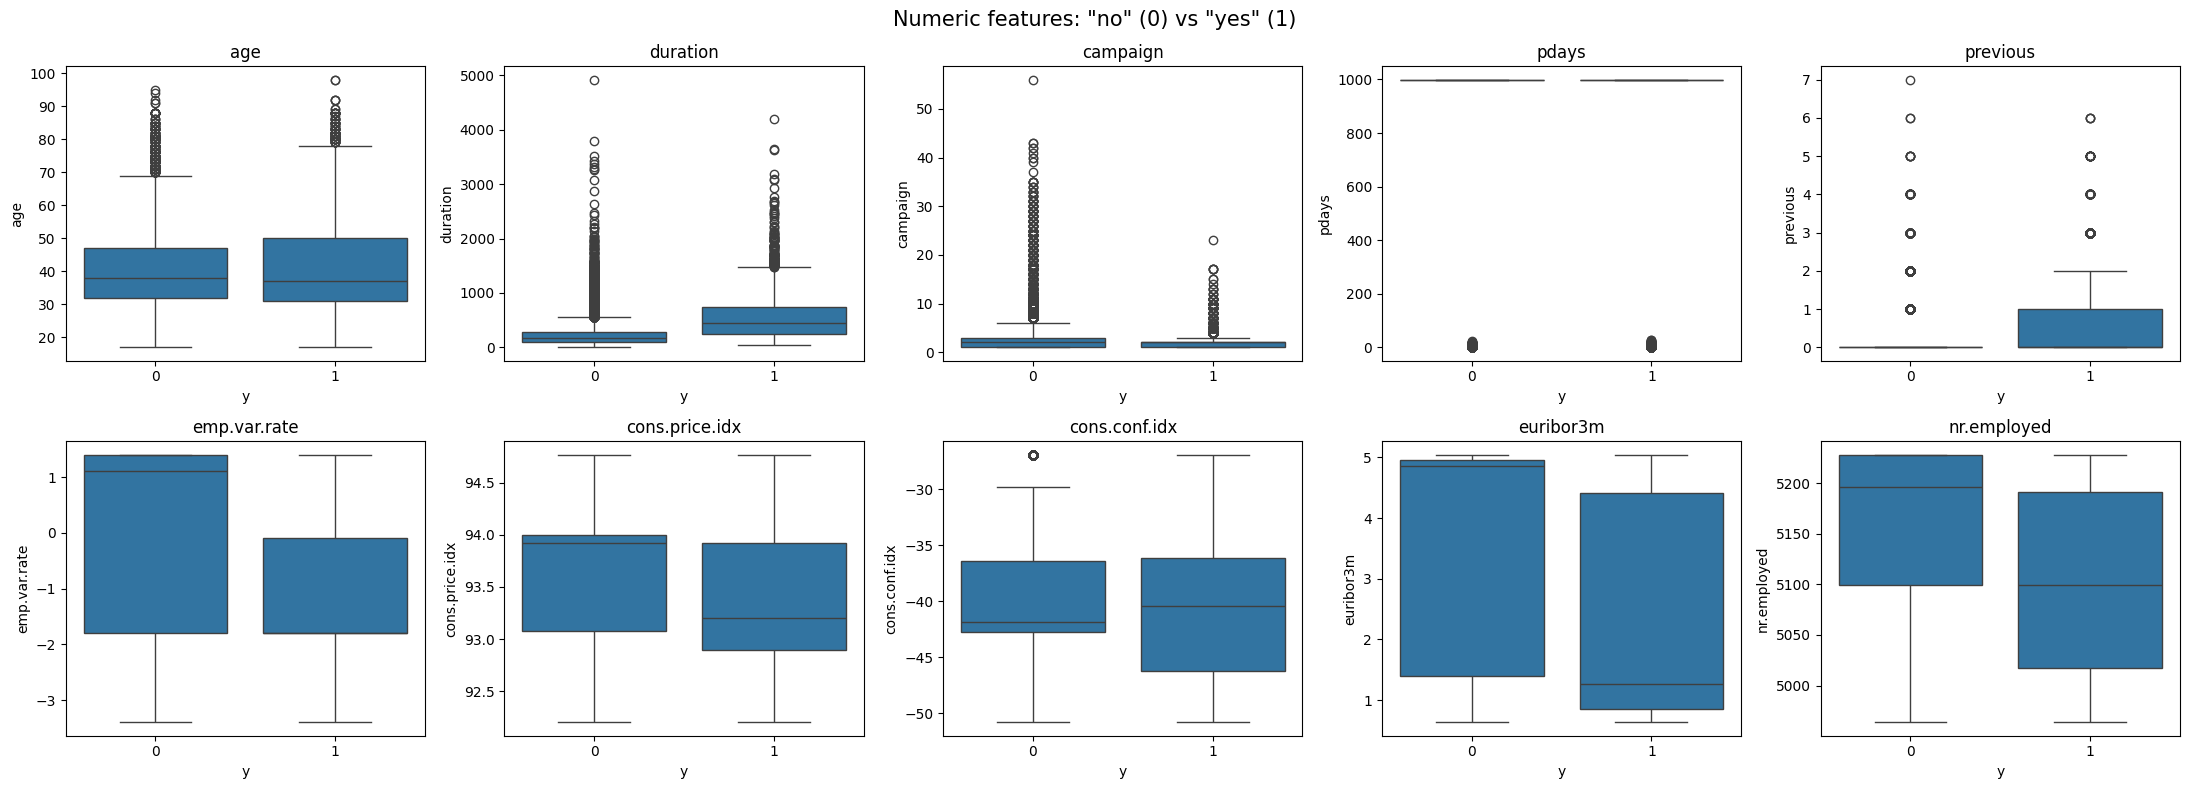

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df, x='y', y=col, ax=ax)
    ax.set_title(col)
plt.suptitle('Numeric features: "no" (0) vs "yes" (1)', fontsize=15)
plt.tight_layout()
plt.show()

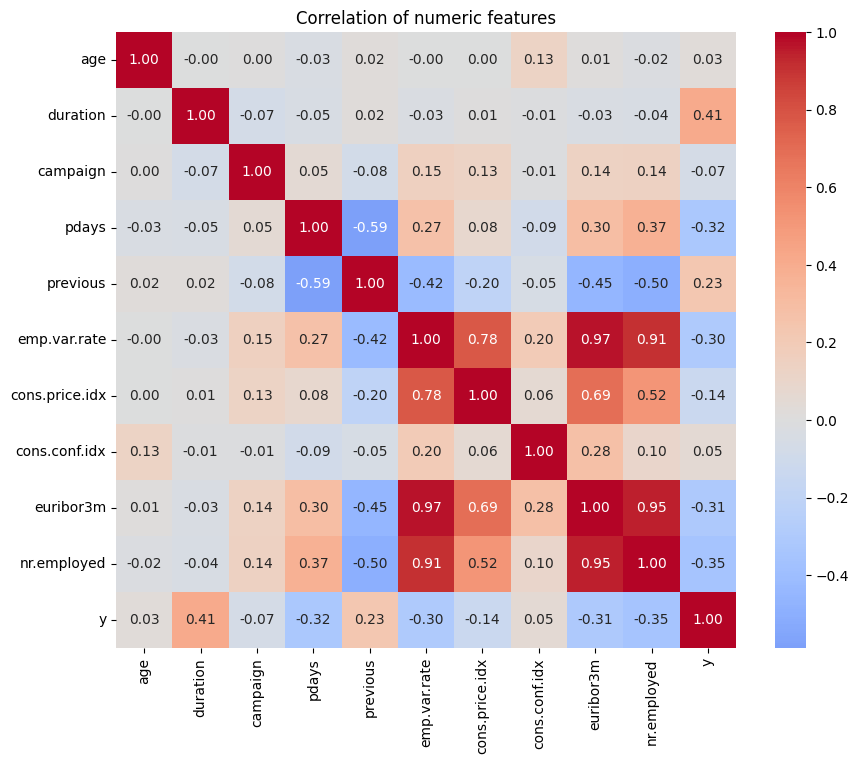

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols + ['y']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numeric features')
plt.show()

**What we see in numeric features:**
- `duration` (length of the call) is very different for "yes" and "no". But we **cannot** use it in the final model: we only know the duration *after* the call, and then we already know the answer. This is called **data leakage**. We will use it only for one comparison experiment.
- Economic features (`euribor3m`, `nr.employed`, `emp.var.rate`) are lower for "yes". When interest rates and employment are low, people open deposits more often.
- `emp.var.rate`, `euribor3m` and `nr.employed` are **strongly correlated with each other** (0.9+). They show almost the same thing — the state of the economy.
- `campaign` has very big outliers (some clients were called 40+ times).
- `pdays = 999` means "never contacted before". It is not a real number of days, so we need to fix it.

### 1.2 Categorical features
For each category we show the **share of "yes"** (subscription rate). The dashed line is the average rate (~11%).

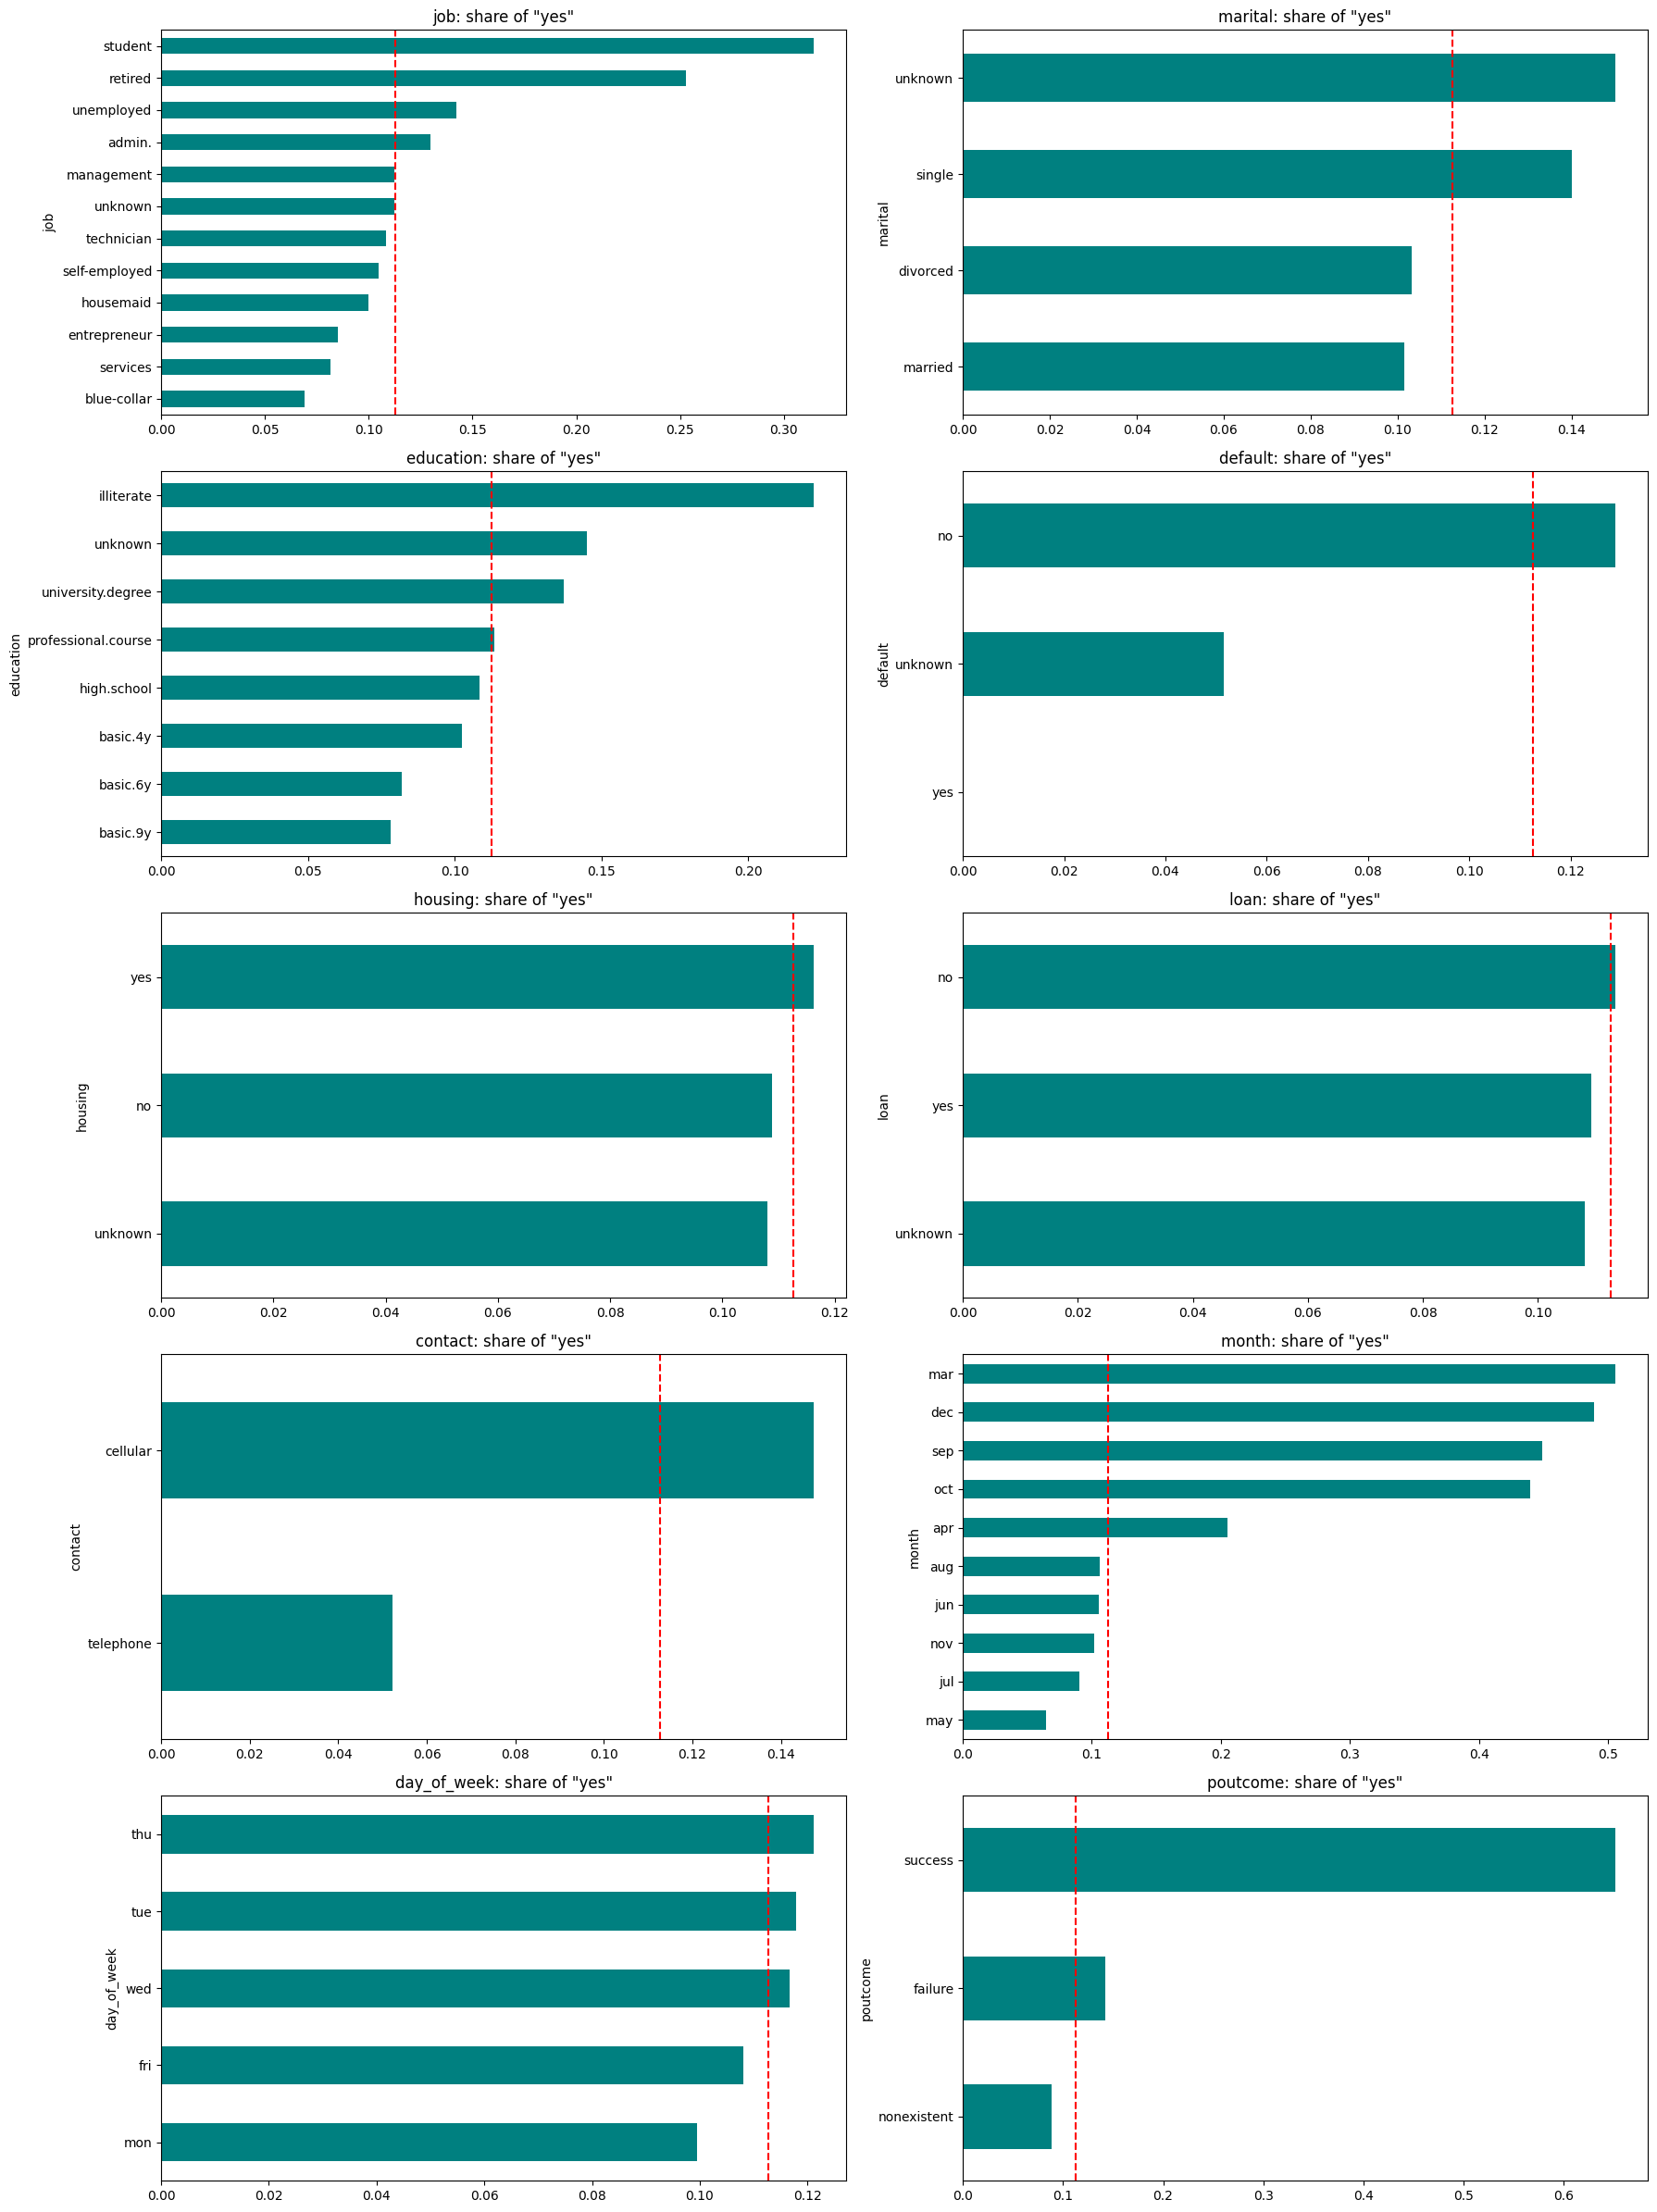

In [9]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']

fig, axes = plt.subplots(5, 2, figsize=(18, 24))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)['y'].mean().sort_values()
    rate.plot(kind='barh', ax=ax, color='teal')
    ax.axvline(df['y'].mean(), color='red', linestyle='--')
    ax.set_title(f'{col}: share of "yes"')
plt.tight_layout()
plt.show()

In [10]:
# How many clients are in each category (small groups are less reliable)
for col in ['job', 'education', 'default', 'poutcome']:
    print(df[col].value_counts(), '\n')

job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64 

education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64 

default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64 

poutcome
nonexistent    35551
failure         4252
success         1373
Name: count, dtype: int64 



### 1.3 Hypotheses
Based on the plots, we think that:

1. **Previous campaign result (`poutcome`) is very important.** If the client said "yes" last time (`success`), the chance of "yes" now is ~65% instead of 11%.
2. **Economy matters.** Low `euribor3m` and low `nr.employed` → more "yes".
3. **Students and retired people** say "yes" more often than other jobs. Blue-collar workers say "yes" less often.
4. **Month matters.** In March, September, October, December the rate is very high (but there are few calls in these months). May has the most calls but a low rate.
5. **Mobile phone (`cellular`)** works better than a home telephone.
6. **Too many calls (`campaign`) do not help** — clients who were called many times rarely say "yes".
7. `default = yes` happens only 3 times — this feature can not help much; `unknown` is the more useful value there.

## 2. Methods and metric

**Task type:** binary classification (yes / no).

**Methods** (simple ones first, then more powerful ones):
- **Logistic Regression** — a simple, fast, easy-to-explain baseline.
- **kNN** — looks at similar clients. Needs scaled numbers.
- **Decision Tree** — easy to understand rules, works with non-linear patterns.
- **XGBoost (boosting)** — many small trees, each one fixes the errors of the previous ones. Usually the best on tabular data.

**Metric: ROC AUC.**
Why not accuracy? Because only 11% say "yes". A model that always says "no" has 89% accuracy but is useless.

ROC AUC shows **how well the model sorts clients**: does it put "yes" clients higher than "no" clients? This is exactly what the bank needs — a list of clients sorted by probability, so the call center calls the best clients first. ROC AUC = 0.5 means random guessing, 1.0 means perfect.

We also look at **recall / precision / F1** for the error analysis at the end.

## 3. Preprocessing

Steps:
1. Remove `duration` (data leakage, see above).
2. **New features** from `pdays`: `contacted_before` (yes/no) and replace 999 with -1.
3. **Group categories**: `basic.4y`, `basic.6y`, `basic.9y`, `illiterate` → `basic` (they behave similarly and `illiterate` has only 18 clients). In `default` the value `yes` (3 clients) → `unknown`.
4. **Outliers in `campaign`**: cut values above the 99th percentile. They are real values (not errors), but very rare and extreme, so we just limit them.
5. New feature `month_quarter` — the season of the call.
6. Split into train (80%) and validation (20%) with `stratify`, so both parts have 11% "yes".
7. One-hot encoding for categories and scaling for numbers (inside a Pipeline, so there is no leakage from validation data).

In [11]:
data = df.drop(columns=['duration']).copy()

# 2. New features from pdays
data['contacted_before'] = (data['pdays'] != 999).astype(int)
data['pdays'] = data['pdays'].replace(999, -1)

# 3. Group rare / similar categories
data['education'] = data['education'].replace(
    {'basic.4y': 'basic', 'basic.6y': 'basic', 'basic.9y': 'basic', 'illiterate': 'basic'})
data['default'] = data['default'].replace({'yes': 'unknown'})

# 5. Season of the call
season = {'mar': 'spring', 'apr': 'spring', 'may': 'spring',
          'jun': 'summer', 'jul': 'summer', 'aug': 'summer',
          'sep': 'autumn', 'oct': 'autumn', 'nov': 'autumn',
          'dec': 'winter', 'jan': 'winter', 'feb': 'winter'}
data['season'] = data['month'].map(season)

data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,contacted_before,season
0,56,housemaid,married,basic,no,no,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,spring
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,spring
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,spring
3,40,admin.,married,basic,no,no,no,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,spring
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,spring


In [12]:
# 6. Train / validation split
X = data.drop(columns=['y'])
y = data['y']
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Val:', X_val.shape)
print('Share of yes - train:', round(y_train.mean(), 3), ' val:', round(y_val.mean(), 3))

Train: (32940, 21)  Val: (8236, 21)
Share of yes - train: 0.113  val: 0.113


In [13]:
# 4. Outliers in campaign: the limit is calculated ONLY on train data
cap = X_train['campaign'].quantile(0.99)
print('99th percentile of campaign:', cap)
print('Rows above the limit in train:', (X_train['campaign'] > cap).sum())

X_train['campaign'] = X_train['campaign'].clip(upper=cap)
X_val['campaign'] = X_val['campaign'].clip(upper=cap)

99th percentile of campaign: 14.0
Rows above the limit in train: 315


In [14]:
# 7. Encoding + scaling
numeric_features = ['age', 'campaign', 'pdays', 'previous', 'contacted_before',
                    'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
categorical_features = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                        'contact', 'month', 'day_of_week', 'poutcome', 'season']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
])

preprocessor.fit(X_train)
print('Number of features after one-hot encoding:', len(preprocessor.get_feature_names_out()))

Number of features after one-hot encoding: 63


## 4. Train 4 models

We put the preprocessor and the model into one **Pipeline**. A small helper function trains a model, calculates ROC AUC on train and validation, and saves the result into a table.

In [15]:
results = []

def evaluate(name, model, params_text, comment=''):
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    auc_train = roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1])
    auc_val = roc_auc_score(y_val, pipe.predict_proba(X_val)[:, 1])
    print(f'{name}:  train AUC = {auc_train:.4f}   val AUC = {auc_val:.4f}')
    results.append({'Model': name, 'Hyperparameters': params_text,
                    'Train ROC AUC': round(auc_train, 4), 'Val ROC AUC': round(auc_val, 4),
                    'Comment': comment})
    return pipe

### 4.1 Logistic Regression
`class_weight='balanced'` tells the model to pay more attention to the rare "yes" class.

In [16]:
logreg = evaluate('Logistic Regression',
                  LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000),
                  'C=1.0, class_weight=balanced')

Logistic Regression:  train AUC = 0.7948   val AUC = 0.8005


### 4.2 kNN
With a small `k` kNN overfits strongly. We try a few values of `k` and choose the best one on validation.

In [17]:
for k in [5, 25, 50, 100, 200]:
    p = Pipeline([('prep', preprocessor), ('model', KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train)
    print(f'k={k:4d}  train AUC={roc_auc_score(y_train, p.predict_proba(X_train)[:,1]):.4f}'
          f'  val AUC={roc_auc_score(y_val, p.predict_proba(X_val)[:,1]):.4f}')

k=   5  train AUC=0.9266  val AUC=0.7403


k=  25  train AUC=0.8490  val AUC=0.7839


k=  50  train AUC=0.8288  val AUC=0.7868


k= 100  train AUC=0.8140  val AUC=0.7966


k= 200  train AUC=0.8061  val AUC=0.8029


In [18]:
knn = evaluate('kNN', KNeighborsClassifier(n_neighbors=100), 'n_neighbors=100')

kNN:  train AUC = 0.8140   val AUC = 0.7966


### 4.3 Decision Tree
A tree without limits remembers all train data (overfitting). We limit the depth.

In [19]:
for depth in [3, 5, 7, 10, None]:
    p = Pipeline([('prep', preprocessor),
                  ('model', DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))]).fit(X_train, y_train)
    print(f'max_depth={str(depth):5s}  train AUC={roc_auc_score(y_train, p.predict_proba(X_train)[:,1]):.4f}'
          f'  val AUC={roc_auc_score(y_val, p.predict_proba(X_val)[:,1]):.4f}')

max_depth=3      train AUC=0.7508  val AUC=0.7608


max_depth=5      train AUC=0.7833  val AUC=0.7916


max_depth=7      train AUC=0.8002  val AUC=0.8022


max_depth=10     train AUC=0.8312  val AUC=0.7655


max_depth=None   train AUC=0.9999  val AUC=0.6296


In [20]:
tree = evaluate('Decision Tree',
                DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=RANDOM_STATE),
                'max_depth=5, min_samples_leaf=50')

Decision Tree:  train AUC = 0.7825   val AUC = 0.7916


### 4.4 XGBoost (default settings)

In [21]:
xgb_default = evaluate('XGBoost (default)',
                       XGBClassifier(random_state=RANDOM_STATE, eval_metric='auc'),
                       'default (n_estimators=100, max_depth=6, learning_rate=0.3)')

XGBoost (default):  train AUC = 0.9030   val AUC = 0.7923


### 4.5 Extra experiment: what if we use `duration`?
Only to show how strong the leakage is. **This model can NOT be used in real life.**

In [22]:
X_train_dur = X_train.copy(); X_val_dur = X_val.copy()
X_train_dur['duration'] = df.loc[X_train.index, 'duration']
X_val_dur['duration'] = df.loc[X_val.index, 'duration']

prep_dur = ColumnTransformer([
    ('num', StandardScaler(), numeric_features + ['duration']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)])
pipe_dur = Pipeline([('prep', prep_dur), ('model', XGBClassifier(random_state=RANDOM_STATE))]).fit(X_train_dur, y_train)
print('XGBoost WITH duration, val AUC:', round(roc_auc_score(y_val, pipe_dur.predict_proba(X_val_dur)[:, 1]), 4))

XGBoost WITH duration, val AUC: 0.9469


With `duration` the AUC jumps a lot. It looks great, but it is "cheating": before the call we don't know how long it will be. So we keep `duration` out of all other models.

## 6. Hyperparameter tuning for XGBoost

(We do section 6 before section 5 so that the final table includes the tuned models.)

We use **cross-validation (5 folds) on the train set** to choose parameters. The validation set is used only at the end to check the result.

### 6.1 Randomized Search (sklearn)
Randomized Search tries random combinations of parameters from a list.

In [23]:
xgb_pipe = Pipeline([('prep', preprocessor),
                     ('model', XGBClassifier(random_state=RANDOM_STATE, eval_metric='auc'))])

param_dist = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [2, 3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'model__subsample': [0.6, 0.8, 1.0],
    'model__colsample_bytree': [0.5, 0.7, 0.9, 1.0],
    'model__min_child_weight': [1, 5, 10, 20],
    'model__gamma': [0, 0.5, 1, 3],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
random_search = RandomizedSearchCV(xgb_pipe, param_dist, n_iter=30, scoring='roc_auc',
                                   cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
random_search.fit(X_train, y_train)

print('Best CV ROC AUC:', round(random_search.best_score_, 4))
best_rs_params = {k.replace('model__', ''): v for k, v in random_search.best_params_.items()}
best_rs_params

Best CV ROC AUC: 0.8005


{'subsample': 0.6,
 'n_estimators': 200,
 'min_child_weight': 1,
 'max_depth': 6,
 'learning_rate': 0.01,
 'gamma': 0.5,
 'colsample_bytree': 1.0}

In [24]:
xgb_rs = evaluate('XGBoost (Randomized Search)',
                  XGBClassifier(**best_rs_params, random_state=RANDOM_STATE, eval_metric='auc'),
                  str(best_rs_params))

XGBoost (Randomized Search):  train AUC = 0.8249   val AUC = 0.8143


### 6.2 Bayesian Optimization (Hyperopt)
Hyperopt is "smarter" than random search: it remembers which parameters were good and tries similar ones next time.

In [25]:
space = {
    'n_estimators': hp.quniform('n_estimators', 100, 500, 50),
    'max_depth': hp.quniform('max_depth', 2, 6, 1),
    'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.2)),
    'subsample': hp.uniform('subsample', 0.6, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 1.0),
    'min_child_weight': hp.quniform('min_child_weight', 1, 20, 1),
    'gamma': hp.uniform('gamma', 0, 3),
}

def to_int(params):
    params = params.copy()
    for p in ['n_estimators', 'max_depth', 'min_child_weight']:
        params[p] = int(params[p])
    return params

def objective(params):
    params = to_int(params)
    pipe = Pipeline([('prep', preprocessor),
                     ('model', XGBClassifier(**params, random_state=RANDOM_STATE, eval_metric='auc'))])
    score = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1).mean()
    return {'loss': -score, 'status': STATUS_OK}   # hyperopt minimizes, so we use -AUC

trials = Trials()
best_hp = fmin(objective, space, algo=tpe.suggest, max_evals=30, trials=trials, show_progressbar=False,
               rstate=np.random.default_rng(RANDOM_STATE))
best_hp_params = {k: (round(float(v), 3) if k not in ['n_estimators', 'max_depth', 'min_child_weight'] else v)
                  for k, v in to_int(best_hp).items()}
print('Best CV ROC AUC:', round(-min(trials.losses()), 4))
best_hp_params

Best CV ROC AUC: 0.8024


{'colsample_bytree': 0.993,
 'gamma': 2.645,
 'learning_rate': 0.033,
 'max_depth': 6,
 'min_child_weight': 4,
 'n_estimators': 500,
 'subsample': 0.677}

In [26]:
xgb_hp = evaluate('XGBoost (Hyperopt)',
                  XGBClassifier(**best_hp_params, random_state=RANDOM_STATE, eval_metric='auc'),
                  str(best_hp_params))

XGBoost (Hyperopt):  train AUC = 0.8430   val AUC = 0.8140


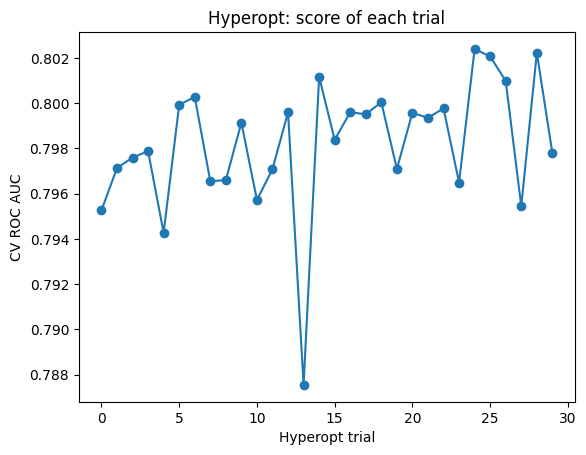

In [27]:
plt.plot(-np.array(trials.losses()), marker='o')
plt.xlabel('Hyperopt trial'); plt.ylabel('CV ROC AUC')
plt.title('Hyperopt: score of each trial')
plt.show()

## 5. Comparison table

In [28]:
comments = {
    'Logistic Regression': 'Good, simple baseline. No overfitting. Easy to explain. Can be used if we need a very simple model.',
    'kNN': 'OK result, but slow on big data and hard to explain. Needs a big k, otherwise it overfits. Not recommended.',
    'Decision Tree': 'Weakest model, but its rules are very easy to read. Good for explaining, not for best quality.',
    'XGBoost (default)': 'Strong overfitting (train 0.90, val 0.79). Default parameters are too complex for this data. Needs tuning.',
    'XGBoost (Randomized Search)': 'BEST model. Highest val AUC and very small overfitting. Recommended for use.',
    'XGBoost (Hyperopt)': 'Almost the same quality as Randomized Search, a bit more overfitting. Also a good choice.',
}
results_df = pd.DataFrame(results)
results_df['Overfit (train - val)'] = (results_df['Train ROC AUC'] - results_df['Val ROC AUC']).round(4)
results_df['Comment'] = results_df['Model'].map(comments)

with pd.option_context('display.max_colwidth', None):
    display(results_df[['Model', 'Hyperparameters', 'Train ROC AUC', 'Val ROC AUC', 'Overfit (train - val)', 'Comment']])

,Model,Hyperparameters,Train ROC AUC,Val ROC AUC,Overfit (train - val),Comment
0,Logistic Regression,"C=1.0, class_weight=balanced",0.7948,0.8005,-0.0057,"Good, simple baseline. No overfitting. Easy to explain. Can be used if we need a very simple model."
1,kNN,n_neighbors=100,0.8140,0.7966,0.0174,"OK result, but slow on big data and hard to explain. Needs a big k, otherwise it overfits. Not recommended."
2,Decision Tree,"max_depth=5, min_samples_leaf=50",0.7825,0.7916,-0.0091,"Weakest model, but its rules are very easy to read. Good for explaining, not for best quality."
3,XGBoost (default),"default (n_estimators=100, max_depth=6, learning_rate=0.3)",0.9030,0.7923,0.1107,"Strong overfitting (train 0.90, val 0.79). Default parameters are too complex for this data. Needs tuning."
4,XGBoost (Randomized Search),"{'subsample': 0.6, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.01, 'gamma': 0.5, 'colsample_bytree': 1.0}",0.8249,0.8143,0.0106,BEST model. Highest val AUC and very small overfitting. Recommended for use.
5,XGBoost (Hyperopt),"{'colsample_bytree': 0.993, 'gamma': 2.645, 'learning_rate': 0.033, 'max_depth': 6, 'min_child_weight': 4, 'n_estimators': 500, 'subsample': 0.677}",0.8430,0.8140,0.0290,"Almost the same quality as Randomized Search, a bit more overfitting. Also a good choice."


**Conclusions from the table:**
- All models are close: val ROC AUC is between **0.79 and 0.81**. Without `duration` it is hard to predict the answer much better — the data simply does not have more information.
- **Logistic Regression** is surprisingly good (0.80) for such a simple model.
- **kNN** and **Decision Tree** overfit very fast if we make them complex (small `k`, big `max_depth`). With good settings they are near 0.79–0.80.
- **XGBoost with default parameters overfits** (train 0.90 vs val 0.79). After tuning, the overfitting is almost gone and XGBoost becomes the best model (**0.814**).
- **Randomized Search vs Hyperopt:** both found a similar result (CV AUC 0.8005 vs 0.8024, val AUC 0.8143 vs 0.8140). Hyperopt was a bit better in cross-validation, Randomized Search was a tiny bit better on validation. The difference is so small that it is just noise. Both work: Randomized Search is simpler, Hyperopt usually finds good parameters faster when the search space is big.
- Both tuned models prefer a **small learning rate** and **subsample < 1** (each tree sees only part of the data) — this is what reduced overfitting.

## 7. Feature importance (best model)

Our best model is the tuned XGBoost (see the table). XGBoost can tell us how much each feature helped to make good splits (importance by `gain`).

Best model: Randomized Search


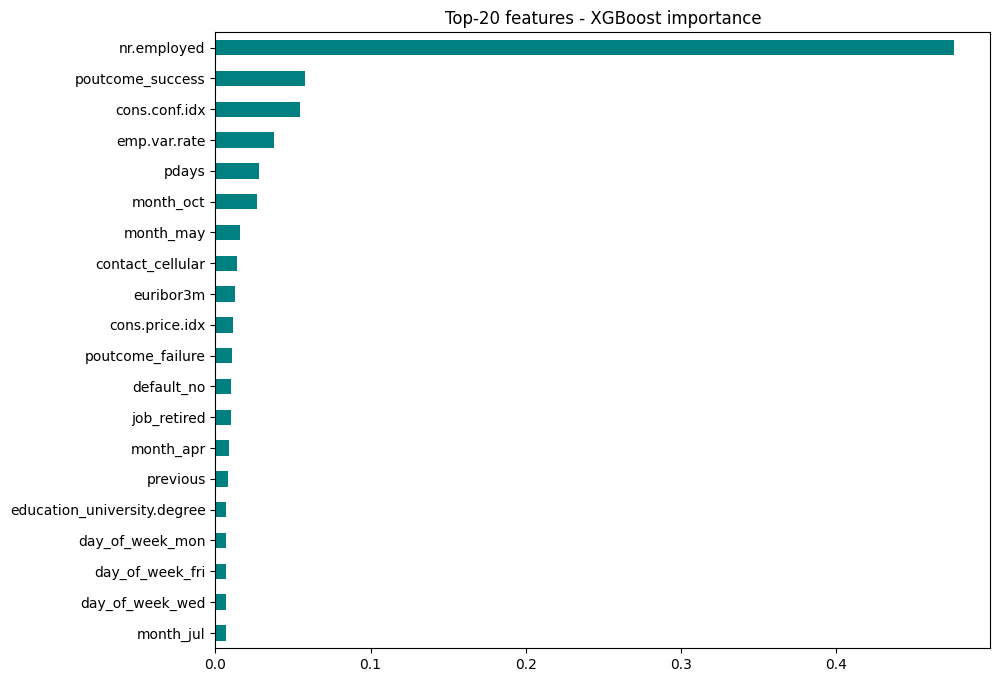

In [29]:
# Choose the tuned XGBoost with the higher validation AUC
best_pipe = xgb_hp if results_df.set_index('Model').loc['XGBoost (Hyperopt)', 'Val ROC AUC'] >= results_df.set_index('Model').loc['XGBoost (Randomized Search)', 'Val ROC AUC'] else xgb_rs
print('Best model:', 'Hyperopt' if best_pipe is xgb_hp else 'Randomized Search')
best_model = best_pipe.named_steps['model']
feature_names = best_pipe.named_steps['prep'].get_feature_names_out()
feature_names = [f.replace('num__', '').replace('cat__', '') for f in feature_names]

importance = pd.Series(best_model.feature_importances_, index=feature_names).sort_values(ascending=False)

importance.head(20).sort_values().plot(kind='barh', figsize=(10, 8), color='teal')
plt.title('Top-20 features - XGBoost importance')
plt.show()

**Does this make sense (common sense)?**

Mostly **yes**:
- `nr.employed` (number of employed people) is by far the most important. It describes the **economic situation** at the time of the call. In the data, almost all "yes" answers happen in periods when this number was low (2008–2010 crisis, when banks offered good deposit rates and people wanted safe savings). So it is logical, but we should be careful: the model learns "which time period" more than "which client". If the economy changes, the model must be retrained.
- `poutcome_success` — a client who said "yes" in the past campaign will probably say "yes" again. Very logical.
- `cons.conf.idx`, `emp.var.rate`, `euribor3m` — again the economy.
- `pdays`, `contact_cellular`, months — information about **how and when** the bank contacts the client. Also logical.

What is a little strange: **personal features** (job, age, education) are low in the list. We expected them to be more important. This means that *when* the bank calls is more important than *who* the bank calls.

## 8. SHAP analysis

Feature importance tells us **which** features are important, but not **in which direction** they work. SHAP shows this: for every client it shows how much each feature pushed the prediction up (towards "yes") or down (towards "no").

In [30]:
X_val_transformed = pd.DataFrame(best_pipe.named_steps['prep'].transform(X_val).toarray()
                                 if hasattr(best_pipe.named_steps['prep'].transform(X_val), 'toarray')
                                 else best_pipe.named_steps['prep'].transform(X_val),
                                 columns=feature_names, index=X_val.index)

explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_val_transformed)

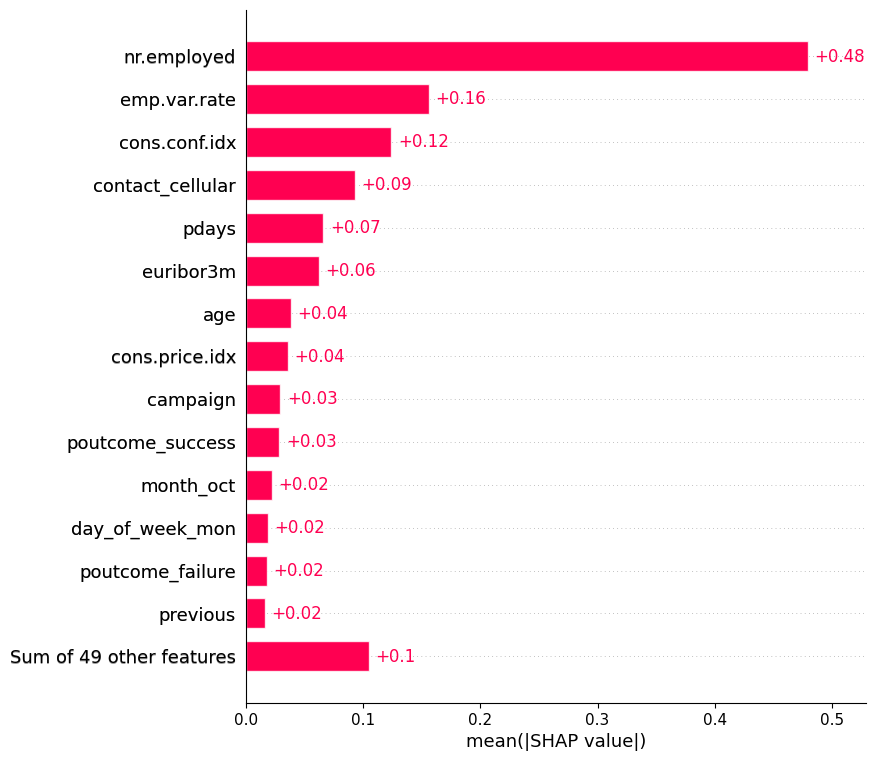

In [31]:
shap.plots.bar(shap_values, max_display=15)

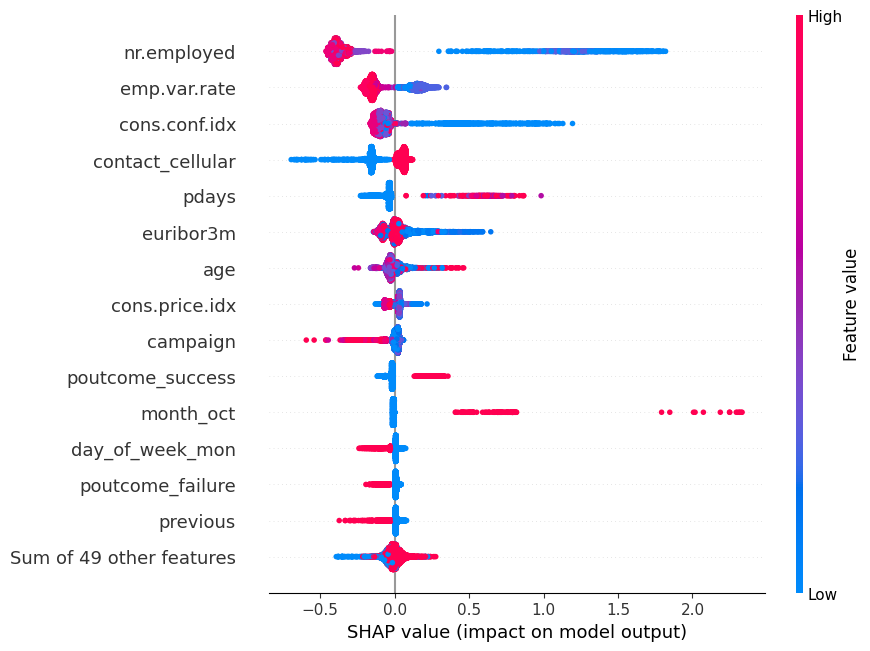

In [32]:
shap.plots.beeswarm(shap_values, max_display=15)

**How to read the beeswarm plot:** every dot is one client. Red = high value of the feature, blue = low value. Dots on the right push the prediction towards "yes", dots on the left — towards "no".

Note: numeric features are scaled (StandardScaler), so "high" / "low" are relative to the average.

### One client as an example
A waterfall plot explains the prediction for one client: we start from the average prediction and each feature adds or subtracts something.

Predicted probability: 0.773  Real answer: 1


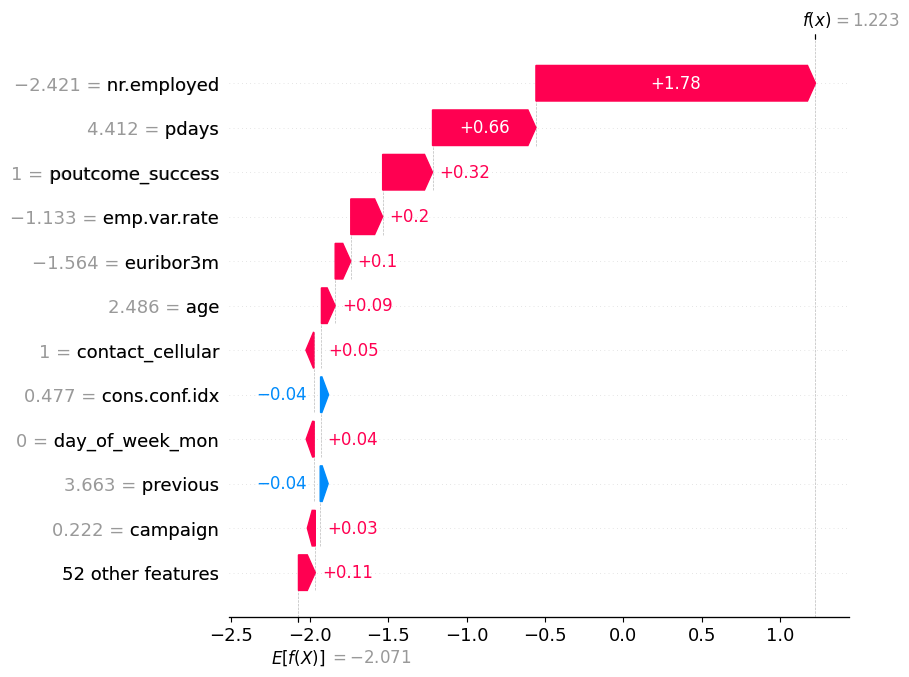

In [33]:
# The client with the highest predicted probability in validation
proba_val = best_pipe.predict_proba(X_val)[:, 1]
idx = int(np.argmax(proba_val))
print('Predicted probability:', round(proba_val[idx], 3), ' Real answer:', y_val.iloc[idx])
shap.plots.waterfall(shap_values[idx], max_display=12)

**What SHAP tells us** (the numbers are in log-odds: positive = more likely "yes"):
- **`nr.employed`, `emp.var.rate`, `cons.conf.idx`, `euribor3m`:** low values (blue) push strongly to "yes". Clients say "yes" in "bad economy" periods with low rates. This confirms **hypothesis 2**.
- **`contact_cellular`:** calling a mobile phone (red) → more "yes", home phone → less. Confirms **hypothesis 5**.
- **`pdays` and `poutcome_success`:** clients who were contacted before, and especially those who said "yes" before, are much more likely to say "yes". Confirms **hypothesis 1**.
- **`campaign`:** many calls (red) push to "no". Calling a client again and again does not help. Confirms **hypothesis 6**.
- **`age`:** high age (red) pushes to "yes" — retired people. Partly confirms **hypothesis 3**.
- **`month_oct`:** October calls have a very big positive effect (hypothesis 4).
- **Monday** calls push a little to "no".

**The example client** (waterfall plot): the model is sure this client says "yes" (probability 0.77, and it was correct). The main reasons: low `nr.employed` (bad economy period), the client was contacted before (`pdays`) and the previous campaign was a success.

## 9. Error analysis

The model gives a probability. To say "yes" or "no" we need a **threshold**. The default 0.5 is bad for imbalanced data (the model would almost never say "yes"). We choose the threshold that gives the best F1 score on validation.

Best threshold: 0.2  F1: 0.531
              precision    recall  f1-score   support

          no       0.95      0.92      0.93      7308
         yes       0.48      0.60      0.53       928

    accuracy                           0.88      8236
   macro avg       0.71      0.76      0.73      8236
weighted avg       0.89      0.88      0.89      8236



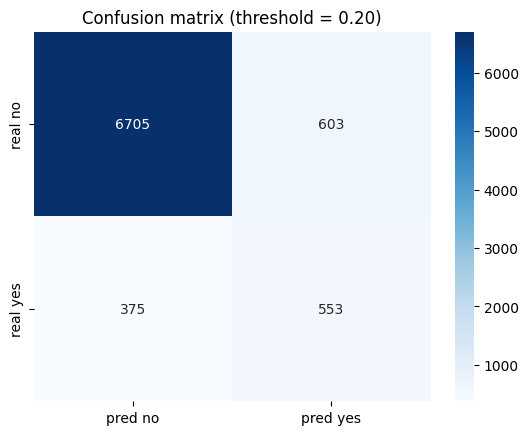

In [34]:
thresholds = np.arange(0.05, 0.8, 0.01)
f1s = [f1_score(y_val, (proba_val >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(f1s))]
print('Best threshold:', round(best_t, 2), ' F1:', round(max(f1s), 3))

pred_val = (proba_val >= best_t).astype(int)
print(classification_report(y_val, pred_val, target_names=['no', 'yes']))

sns.heatmap(confusion_matrix(y_val, pred_val), annot=True, fmt='d', cmap='Blues',
            xticklabels=['pred no', 'pred yes'], yticklabels=['real no', 'real yes'])
plt.title(f'Confusion matrix (threshold = {best_t:.2f})')
plt.show()

In [35]:
# Put the predictions next to the original data
errors = X_val.copy()
errors['real'] = y_val.values
errors['proba'] = proba_val
errors['pred'] = pred_val
errors['group'] = np.select(
    [(errors.real == 1) & (errors.pred == 1), (errors.real == 0) & (errors.pred == 0),
     (errors.real == 1) & (errors.pred == 0), (errors.real == 0) & (errors.pred == 1)],
    ['TP (correct yes)', 'TN (correct no)', 'FN (missed yes)', 'FP (false alarm)'], default='?')
errors['group'].value_counts()

group
TN (correct no)     6705
FP (false alarm)     603
TP (correct yes)     553
FN (missed yes)      375
Name: count, dtype: int64

In [36]:
# Average numeric values in each group
errors.groupby('group')[['age', 'campaign', 'contacted_before', 'euribor3m', 'nr.employed', 'proba']].mean().round(3)

,age,campaign,contacted_before,euribor3m,nr.employed,proba
group,,,,,,
FN (missed yes),38.995,2.504,0.005,3.565,5172.402,0.079
FP (false alarm),41.615,1.968,0.159,1.040,5048.634,0.354
TN (correct no),39.856,2.644,0.004,4.086,5188.621,0.065
TP (correct yes),41.423,1.736,0.335,1.033,5038.449,0.435


In [37]:
# Categorical features: share of each value in each group
for col in ['poutcome', 'contact', 'month']:
    print(f'--- {col} ---')
    print((pd.crosstab(errors['group'], errors[col], normalize='index') * 100).round(1), '\n')

--- poutcome ---
poutcome          failure  nonexistent  success
group                                          
FN (missed yes)       8.5         90.9      0.5
FP (false alarm)     24.9         61.4     13.8
TN (correct no)       8.4         91.3      0.4
TP (correct yes)     17.2         52.1     30.7 

--- contact ---
contact           cellular  telephone
group                                
FN (missed yes)       69.6       30.4
FP (false alarm)      88.9       11.1
TN (correct no)       58.1       41.9
TP (correct yes)      91.0        9.0 

--- month ---
month              apr   aug  dec   jul   jun   mar   may   nov   oct  sep
group                                                                     
FN (missed yes)    7.5  13.3  0.0  21.1   9.3   0.0  40.0   8.0   0.0  0.8
FP (false alarm)  15.8  17.1  3.2   7.3  15.8   8.8   5.8   7.0  11.3  8.1
TN (correct no)    5.0  14.9  0.0  18.7  12.8   0.0  37.7  10.6   0.1  0.1
TP (correct yes)  15.6  13.0  2.9   6.9  15.0  11.0   5.8 

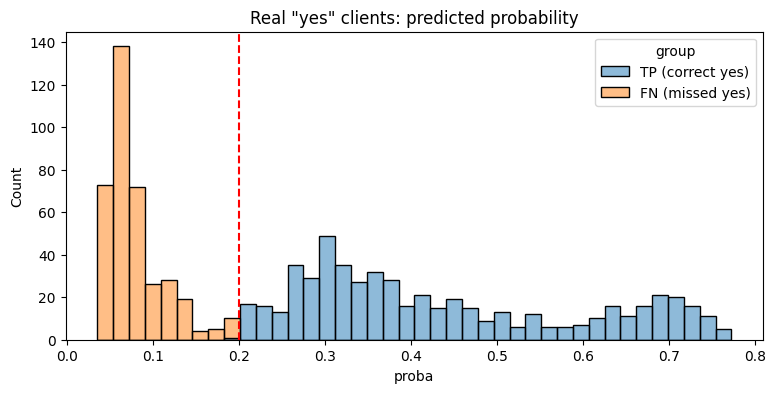

In [38]:
# Probability distribution of the missed "yes" clients
plt.figure(figsize=(9, 4))
sns.histplot(data=errors[errors.real == 1], x='proba', hue='group', bins=40)
plt.axvline(best_t, color='red', linestyle='--', label='threshold')
plt.title('Real "yes" clients: predicted probability')
plt.show()

**What we see in the errors:**

With threshold 0.20 the model finds **60% of all "yes" clients** (recall), and about **half** of the clients it marks as "yes" really say "yes" (precision 0.48). For comparison, random calling gives only 11% "yes". So the model makes the call center about **4 times more effective**.

**Missed "yes" (FN, 375 clients)** look almost exactly like the correct "no" clients (TN):
- they were **not contacted before** (`contacted_before` ≈ 0, `poutcome = nonexistent` 91%),
- they were called in a **"good economy" period** (high `euribor3m` and `nr.employed`), often in **May**,
- the model gave them a very low probability (0.08 on average).

So the model has nothing to "catch" for these clients: they are new clients, called at a "bad" time. The data does not tell us why they said "yes".

**False alarms (FP, 603 clients)** look like the correct "yes" clients (TP): called during the crisis period, on a mobile phone, often contacted before. Some of them had a previous success but still said "no".

**How to improve:**
1. **More data about the client:** income, account balance, how long they are a client, other bank products, deposit history. Now the model mostly knows about the economy, not about the person.
2. **Data about the deposit offer itself:** the interest rate the bank offered. Clients compare it with `euribor3m`.
3. **More features:** e.g. a flag "called in May", interactions like `age × job`, a "number of calls today" feature.
4. **Choose the threshold based on business costs:** if a call is cheap and a new deposit brings a lot of money, use a lower threshold (more recall). 
5. **Try other models:** LightGBM / CatBoost, or a simple ensemble (average of Logistic Regression and XGBoost).

## 10. Conclusions

**What we did**
- Explored 41,176 clients (after removing 12 duplicates). Only 11.3% say "yes" → imbalanced data → we used **ROC AUC** as the main metric.
- Removed `duration` because it causes data leakage (with it val AUC = 0.95, but such a model is useless in real life).
- Preprocessing: kept `unknown` as a category, grouped rare categories in `education` and `default`, made `contacted_before` and `season` features, fixed `pdays = 999`, cut outliers in `campaign` at the 99th percentile, one-hot encoding + scaling in a Pipeline.
- Trained Logistic Regression, kNN, Decision Tree and XGBoost, then tuned XGBoost with Randomized Search and Hyperopt.

**Results**

| Model | Val ROC AUC |
|---|---|
| Logistic Regression | 0.8005 |
| kNN (k=100) | 0.7966 |
| Decision Tree (depth 5) | 0.7916 |
| XGBoost default | 0.7923 |
| **XGBoost Randomized Search** | **0.8143** |
| XGBoost Hyperopt | 0.8140 |

- The best model is the **tuned XGBoost** (ROC AUC ≈ 0.814). With threshold 0.20 it finds 60% of the "yes" clients, and every second client it chooses really subscribes (vs. 1 of 9 with random calling).
- The most important factors are the **economic situation** (`nr.employed`, `emp.var.rate`, `cons.conf.idx`, `euribor3m`), the **previous campaign result**, and **how/when the client is contacted** (mobile phone, month, number of calls).

**Recommendations for the bank**
- Call first the clients with a high model score, especially those who said "yes" before.
- Use mobile phones. Don't call the same client too many times.
- Retrain the model regularly, because it depends a lot on the economy.

**What could be done next**
- Get more client data (income, balance, products) and the offered deposit rate.
- Try LightGBM / CatBoost and model ensembles.
- Choose the threshold together with the business, using the real cost of a call and the profit from a deposit.